# Point and interval estimation

A sample does not reveal a population parameter exactly. It gives us evidence with which to estimate it. A useful analysis therefore reports both a plausible value for the quantity of interest and how uncertain that estimate is.

This chapter builds on the sampling distributions in [Chapter 4](04_sampling_lln_clt.md). It connects those ideas to estimation and to **Lab 5: Calories & Workouts**, whose questions concern average calories per workout, differences between workout types, and the proportion of workouts meeting an intensity threshold.

By the end, you should be able to distinguish an estimator from an estimate, assess basic properties of an estimator, construct and interpret confidence intervals for a mean and a proportion, compare two means, and explain how sample size affects precision.

## 5.1 From a sample to an estimate

A **parameter** describes a population or probability model. It is fixed for the population under discussion, although it is usually unknown. A **statistic** is calculated from sample data and changes from sample to sample. When a statistic is used to estimate a parameter, it is called an **estimator**.

For a population mean $\mu$, the sample mean

$$
\bar X = \frac{1}{n}\sum_{i=1}^{n}X_i
$$

is an estimator. Before collecting data, $\bar X$ is random. After observing the sample, its realised value $\bar x$ is a **point estimate** of $\mu$. For a population proportion $p$, the sample proportion

$$
\hat p = \frac{1}{n}\sum_{i=1}^{n} I_i
$$

is a point estimator, where $I_i=1$ if observation $i$ meets the definition of a success and $I_i=0$ otherwise.

A point estimate is compact, but it does not show the sampling variability that produced it. Two studies can report the same sample mean while having very different sample sizes and therefore very different precision. An **interval estimate** gives a range of parameter values consistent with a specified procedure and confidence level.

### What makes an estimator useful?

Several properties help us compare estimators:

- **Bias.** The bias of an estimator $\hat\theta$ is $E(\hat\theta)-\theta$. It is unbiased when its expected value equals the target parameter. Under random sampling, the sample mean is unbiased for $\mu$.
- **Variance.** A low-variance estimator changes less across repeated samples. It is more precise, all else equal.
- **Mean squared error.** The mean squared error combines variance and bias:

  $$
  \operatorname{MSE}(\hat\theta)
  = E\!\left[(\hat\theta-\theta)^2\right]
  = \operatorname{Var}(\hat\theta)+\operatorname{Bias}(\hat\theta)^2.
  $$

- **Consistency.** An estimator is consistent if it converges in probability to the parameter as the sample size grows. Under suitable random-sampling conditions, the sample mean is consistent for the population mean.

These are properties of a procedure over repeated samples, not guarantees about one particular dataset. A large sample can make a noisy estimate more precise, but it cannot repair systematic selection bias or poor measurement.

## 5.2 Standard errors and confidence intervals

The **standard error (SE)** estimates the standard deviation of an estimator's sampling distribution. It measures sampling variability, not the spread of individual observations. For a sample mean with unknown population standard deviation,

$$
\widehat{\operatorname{SE}}(\bar X)=\frac{s}{\sqrt n},
$$

where $s$ is the sample standard deviation. For an independent sample proportion,

$$
\widehat{\operatorname{SE}}(\hat p)
\approx \sqrt{\frac{\hat p(1-\hat p)}{n}}.
$$

A confidence interval combines an estimate with its estimated standard error and a critical value. A general form is

$$
\text{estimate}\ \pm\ \text{critical value}\times\text{standard error}.
$$

For example, when observations are independent and sampled from a normal population, a $100(1-\alpha)\%$ confidence interval for the mean with unknown population standard deviation is

$$
\bar x \ \pm\ t_{1-\alpha/2,\,n-1}\frac{s}{\sqrt n}.
$$

Here $t_{1-\alpha/2,\,n-1}$ is a quantile of Student's $t$ distribution with $n-1$ degrees of freedom. The interval uses the $t$ distribution because the population standard deviation is unknown and is estimated by $s$. For large samples, the $t$ critical value approaches the corresponding standard-normal value.

### What does 95% confidence mean?

The population parameter is fixed; the interval changes from sample to sample. A **95% confidence procedure** is one that, under its assumptions, produces intervals containing the true parameter in 95% of repeated samples. Once one particular interval has been calculated, it either contains the fixed parameter or it does not. The 95% describes the long-run performance of the procedure, not a 95% probability that this already-calculated interval contains the parameter.

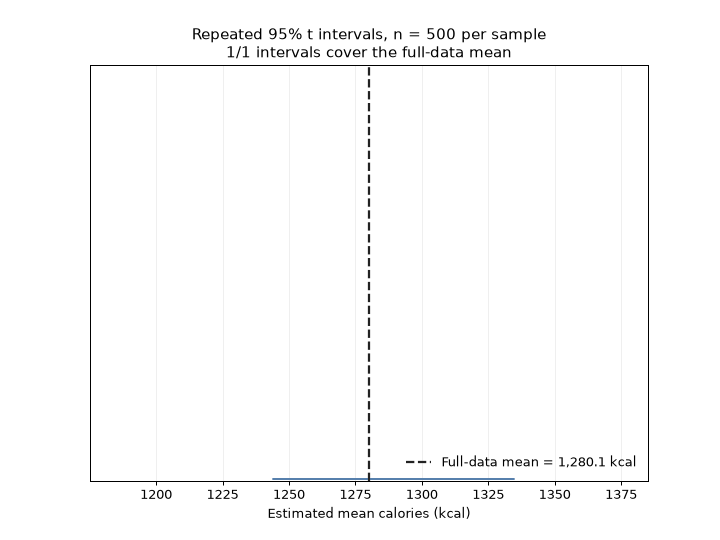

*Figure 5.1. The animation uses the empirical distribution of the 20,000 workout records as a teaching population. In this simulation, 188 of 200 intervals cover the full-data mean. It illustrates repeated-sample coverage; it is not evidence that the source records represent a wider population.*

The interval describes uncertainty from the sampling model. It does not account automatically for nonresponse, measurement error, an unrepresentative sample, dependence between observations, or a data-cleaning decision that changes the target.

## 5.3 Estimating a mean

Suppose we want the average calories burned per recorded workout. If the records are independent and the sample is reasonably representative of the target population, use the sample mean as a point estimate and a $t$ interval to express sampling uncertainty:

$$
\bar x \ \pm\ t_{0.975,\,n-1}\frac{s}{\sqrt n}
$$

for a 95% interval. The interval is in the same units as the measurement. If the sample is small and the calorie distribution is strongly skewed or has influential outliers, the $t$ interval may not perform well; inspect the data and consider a design-appropriate robust or bootstrap method. A larger sample helps the normal approximation to the mean, but does not make dependent records independent.

### Lab example: prepare the workout data

The cells below use the same public CSV as the lab. Run them in order: the first installs the required packages and the next loads the data. If you have downloaded the CSV, replace `url` with its local file path.



In [ ]:
%pip install pandas scipy matplotlib seaborn statsmodels

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/kflisikowsky/analiza_danych_projekt_zespolowy/refs/heads/main/Life%20Style%20Data/Final_data.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(20000, 54)


,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,...,cal_from_macros,pct_carbs,protein_per_kg,pct_HRR,pct_maxHR,cal_balance,lean_mass_kg,expected_burn,Burns Calories (per 30 min)_bc,Burns_Calories_Bin
0,34.91,Male,65.27,1.62,188.58,157.65,69.05,1.00,1080.90,Strength,...,2139.59,0.500432,1.624789,0.741237,0.835985,725.10,47.777394,685.1600,7.260425e+19,Medium
1,23.37,Female,56.41,1.55,179.43,131.75,73.18,1.37,1809.91,HIIT,...,1711.65,0.500850,1.514093,0.551247,0.734270,-232.91,40.809803,978.6184,1.020506e+20,High
2,33.20,Female,58.98,1.67,175.04,123.95,54.96,0.91,802.26,Cardio,...,1965.92,0.500610,1.663445,0.574534,0.708124,805.74,44.635580,654.5266,1.079607e+20,High
3,38.69,Female,93.78,1.70,191.21,155.10,50.07,1.10,1450.79,HIIT,...,1627.28,0.499533,0.862017,0.744155,0.811150,1206.21,63.007432,773.6300,8.987921e+19,High
4,45.09,Male,52.42,1.88,193.58,152.88,70.84,1.08,1166.40,Strength,...,2659.23,0.500581,2.538153,0.668405,0.789751,303.60,43.347504,711.4176,5.264685e+19,Low




The cleaning rule below excludes missing values and negative calorie values. It does not silently remove large positive values: investigate plausible extremes using the data documentation and a stated rule before deciding whether to exclude them.



In [2]:
workouts = df[["Calories_Burned", "Workout_Type"]].copy()
workouts.columns = ["calories", "workout_type"]
workouts = workouts.dropna()
workouts = workouts[workouts["calories"] >= 0]
workouts["workout_type"] = workouts["workout_type"].str.strip().str.lower()

print(f"Workouts kept: {len(workouts):,}")
workouts.head()

Workouts kept: 20,000


,calories,workout_type
0,1080.90,strength
1,1809.91,hiit
2,802.26,cardio
3,1450.79,hiit
4,1166.40,strength




The code treats each retained row as an independent workout. If one person contributes several workouts, records from that person may be correlated. State this limitation; for person-level conclusions, aggregate at the participant level or use a method that accounts for repeated measurements.

Calculate the mean, its estimated SE and the 95% $t$ interval:



In [3]:
from scipy import stats

calories = workouts["calories"]
n = len(calories)
mean = calories.mean()
se = stats.sem(calories)
ci = stats.t.interval(0.95, df=n - 1, loc=mean, scale=se)

print(f"Mean: {mean:.1f} kcal")
print(f"Standard error: {se:.1f} kcal")
print(f"95% t interval: {ci[0]:.1f} to {ci[1]:.1f} kcal")

Mean: 1280.1 kcal
Standard error: 3.6 kcal
95% t interval: 1273.1 to 1287.1 kcal




Report the estimate with its units and interval. For example: “The sample mean was $\bar x$ kcal per recorded workout (95% $t$ CI: $L$ to $U$ kcal), under the stated sampling and independence assumptions.” Do not call the interval a range containing 95% of individual workouts; it estimates uncertainty about the **population mean**.

For this dataset, all 20,000 records have finite, non-negative `Calories_Burned` values and a non-empty workout type, so this cleaning rule retains all rows. The resulting sample mean is **1,280.1 kcal**, with **SE 3.6 kcal** and a **95% $t$ interval of 1,273.1 to 1,287.1 kcal**.

These are calculations on this dataset. The file does not document a probability-sampling design or provide a participant ID. Consequently, the interval is conditional on treating records as independent and must not be read as proof that the dataset represents a wider population.

## 5.4 Comparing two means

To compare two workout types, define the direction of subtraction first. For example,

$$
\Delta = \mu_{\text{running}}-\mu_{\text{walking}}.
$$

A positive estimate means that the sample mean for running is higher. For independent groups that may have different variances or sample sizes, Welch's interval is generally preferable to a pooled-variance interval:

$$
(\bar x_1-\bar x_2)\ \pm\ t_{1-\alpha/2,\,\nu}
\sqrt{\frac{s_1^2}{n_1}+\frac{s_2^2}{n_2}},
$$

where the Welch--Satterthwaite degrees of freedom are

$$
\nu =
\frac{\left(s_1^2/n_1+s_2^2/n_2\right)^2}
{\left(s_1^2/n_1\right)^2/(n_1-1)+\left(s_2^2/n_2\right)^2/(n_2-1)}.
$$

This method does not assume equal population variances. It still assumes independent observations within and between groups, and a sufficiently well-behaved sampling distribution of the difference. If the same people contribute observations to both categories, the independent-groups formula is not appropriate; analyse paired differences instead.



In [4]:
from scipy import stats

hiit = workouts.loc[workouts["workout_type"] == "hiit", "calories"]
cardio = workouts.loc[workouts["workout_type"] == "cardio", "calories"]
comparison = stats.ttest_ind(hiit, cardio, equal_var=False)
ci = comparison.confidence_interval(confidence_level=0.95)

difference = hiit.mean() - cardio.mean()
print(f"HIIT - cardio: {difference:.1f} kcal")
print(f"Welch 95% interval: {ci.low:.1f} to {ci.high:.1f} kcal")

HIIT - cardio: 441.0 kcal
Welch 95% interval: 422.6 to 459.4 kcal




Interpret the estimate and both interval endpoints in the chosen order. If the interval includes zero, the data are compatible with no difference as well as with some positive or negative differences at this confidence level. This alone does not establish that the workout types are equivalent, nor that workout type causes a difference in calories.

In this dataset, the estimated difference **HIIT minus cardio** is **441.0 kcal** (Welch 95% CI: **422.6 to 459.4 kcal**; $n_{\text{HIIT}}=4{,}974$, $n_{\text{cardio}}=4{,}923$). This describes the two groups in this file; it is not a causal comparison.

## 5.5 Estimating a proportion

Choose a meaningful binary rule before calculating a proportion. Here a **success** is a recorded workout with at least 1,500 kcal. A 300 kcal threshold would classify every record in this particular dataset as a success and would not make a useful comparison. If $k$ out of $n$ eligible workouts meet the rule, the point estimate is

$$
\hat p=\frac{k}{n}.
$$

The normal-approximation 95% interval is

$$
\hat p \ \pm\ 1.96\sqrt{\frac{\hat p(1-\hat p)}{n}}.
$$

It can extend below 0 or above 1 and can be unreliable when there are few successes or failures. A **Wilson interval** is usually a better default for a single proportion. With $z=1.96$ for 95% confidence, it is

$$
\frac{
\hat p+\frac{z^2}{2n}
\ \pm\
z\sqrt{\frac{\hat p(1-\hat p)}{n}+\frac{z^2}{4n^2}}
}{
1+\frac{z^2}{n}
}.
$$

The plus and minus signs give the upper and lower endpoints, respectively. Unlike the basic normal interval, the Wilson interval stays between zero and one and behaves better when the observed proportion is near a boundary.



In [5]:
from statsmodels.stats.proportion import proportion_confint

threshold = 1500
successes = (workouts["calories"] >= threshold).sum()
n = len(workouts)
p_hat = successes / n

normal_ci = proportion_confint(successes, n, method="normal")
wilson_ci = proportion_confint(successes, n, method="wilson")

print(f"At least {threshold:,} kcal: {successes:,}/{n:,} = {p_hat:.1%}")
print(f"Normal 95% interval: {normal_ci[0]:.1%} to {normal_ci[1]:.1%}")
print(f"Wilson 95% interval: {wilson_ci[0]:.1%} to {wilson_ci[1]:.1%}")

At least 1,500 kcal: 5,628/20,000 = 28.1%
Normal 95% interval: 27.5% to 28.8%
Wilson 95% interval: 27.5% to 28.8%




The normal interval above is clipped to the possible range $[0,1]$ for display; clipping does not fix a poor normal approximation. Compare it with Wilson, especially when $n\hat p$ or $n(1-\hat p)$ is small. A proportion estimates the fraction of the defined population meeting the rule, not the average calorie expenditure.

For this dataset, **5,628 of 20,000 workouts (28.14%)** meet the 1,500 kcal threshold. The 95% normal interval is **27.52% to 28.76%** and the 95% Wilson interval is **27.52% to 28.77%**. The close agreement is expected here because the sample is large and contains many successes and failures; Wilson remains a sound default.

## 5.6 Precision and choosing a sample size

For a mean, the approximate margin of error is $E=z_{1-\alpha/2}\sigma/\sqrt n$. Solving for $n$ gives

$$
n \approx \left(\frac{z_{1-\alpha/2}\sigma}{E}\right)^2.
$$

For a proportion, replacing the unknown $p$ with a planning value gives

$$
n \approx \frac{z_{1-\alpha/2}^{\,2}p(1-p)}{E^2}.
$$

Round both results **up** to the next whole observation. These are planning approximations: the mean formula needs a pilot estimate or defensible value for $\sigma$, and the proportion formula needs a planning value for $p$. Taking $p=0.5$ gives the largest required sample size for a given margin of error because $p(1-p)$ is then largest.



In [6]:
from math import ceil

z = stats.norm.ppf(0.975)
mean_margin = 25  # kcal
proportion_margin = 0.05

n_for_mean = ceil((z * calories.std() / mean_margin) ** 2)
n_for_proportion = ceil(z**2 * p_hat * (1 - p_hat) / proportion_margin**2)
n_conservative = ceil(z**2 * 0.5 * (1 - 0.5) / proportion_margin**2)

print(f"For a mean within {mean_margin} kcal: {n_for_mean:,}")
print(f"For a proportion within 0.05 (observed p): {n_for_proportion:,}")
print(f"For a proportion within 0.05 (p = 0.5): {n_conservative:,}")

For a mean within 25 kcal: 1,551
For a proportion within 0.05 (observed p): 311
For a proportion within 0.05 (p = 0.5): 385




For this file, using its sample standard deviation as a pilot gives an approximate **1,551 workouts** for a 25 kcal margin of error. For a 0.05 proportion margin, the observed $\hat p$ gives **311 workouts**, while the conservative $p=0.5$ choice gives **385**. These are planning approximations, not a guarantee of precision.

The normal critical value gives an approximate planning calculation for the mean; a small pilot or small final sample may require a $t$-based calculation. Also inflate the planned sample if nonresponse or unusable records are expected. Sample-size calculations target random error only: they do not eliminate bias or repair a flawed design.

## 5.7 Visualise the data and the uncertainty

A histogram shows the shape and spread of the observed calorie values. A point-and-interval plot compares group means and their 95% $t$ intervals. These graphs complement the numerical estimates; they do not replace a clear definition of the population, units, cleaning rules or assumptions.

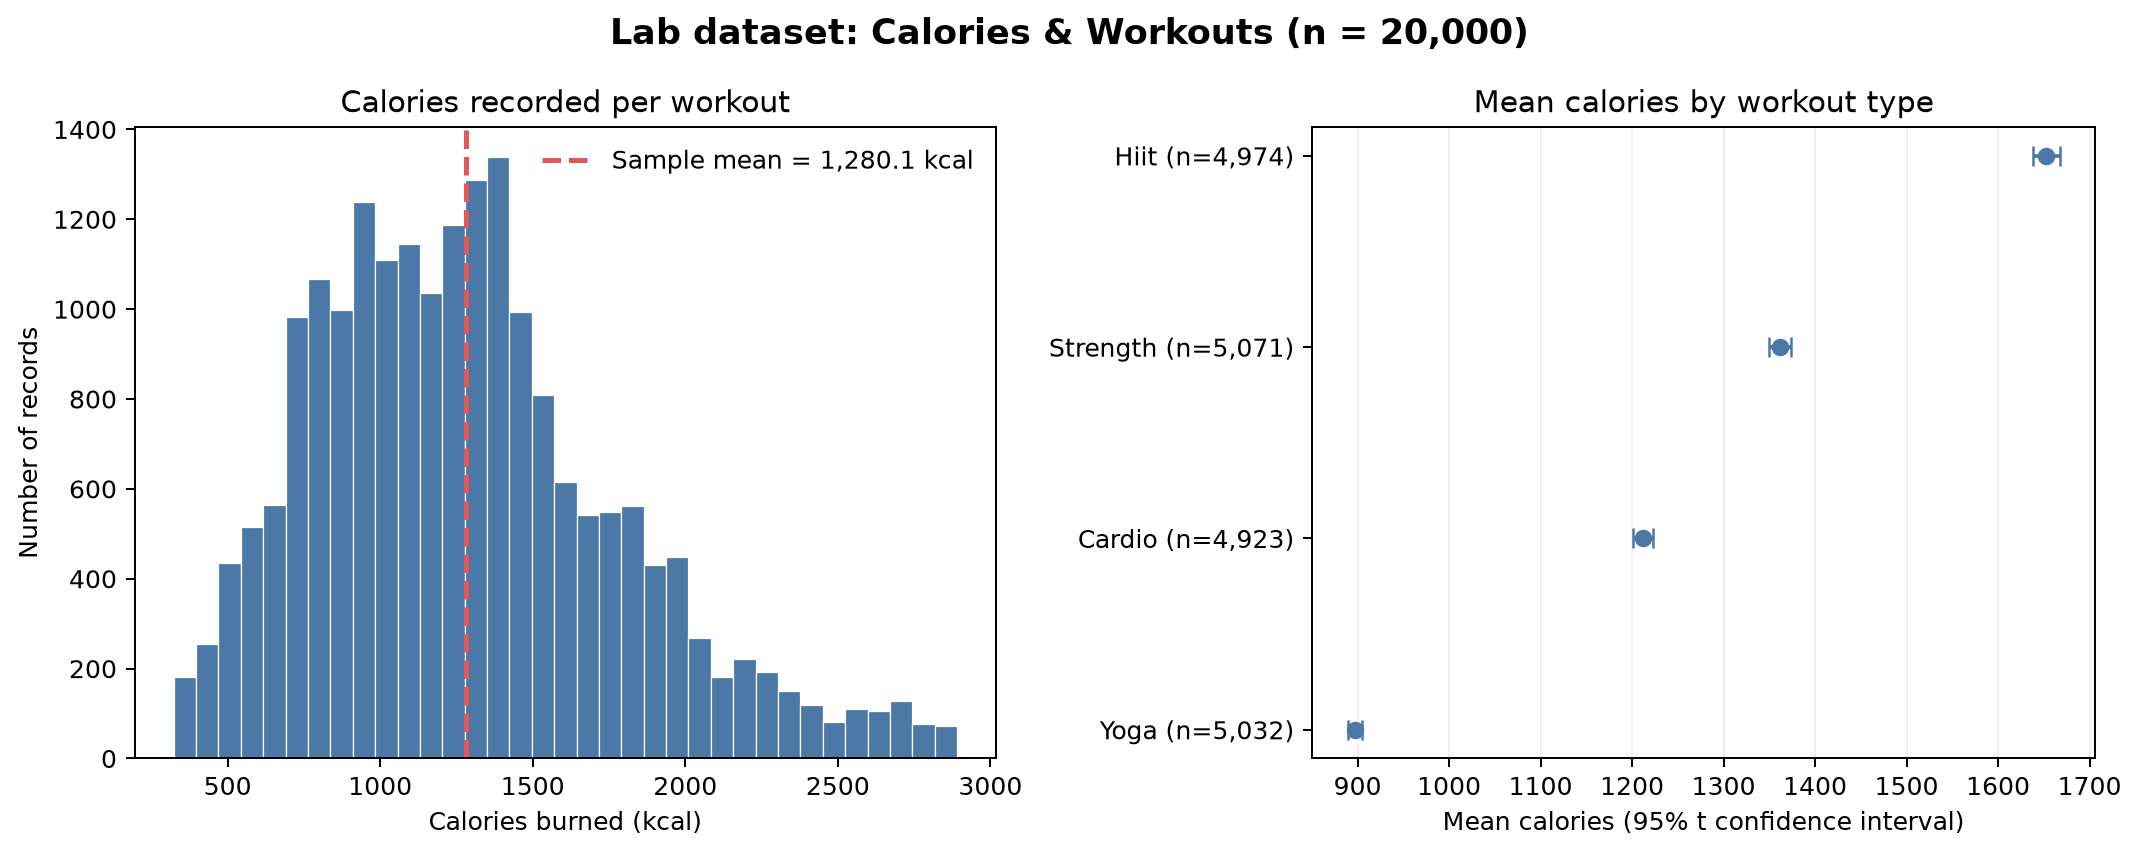

*Figure 5.2. Both panels use the 20,000 rows from the laboratory CSV. Group intervals show uncertainty in means, not the spread of individual workouts.*



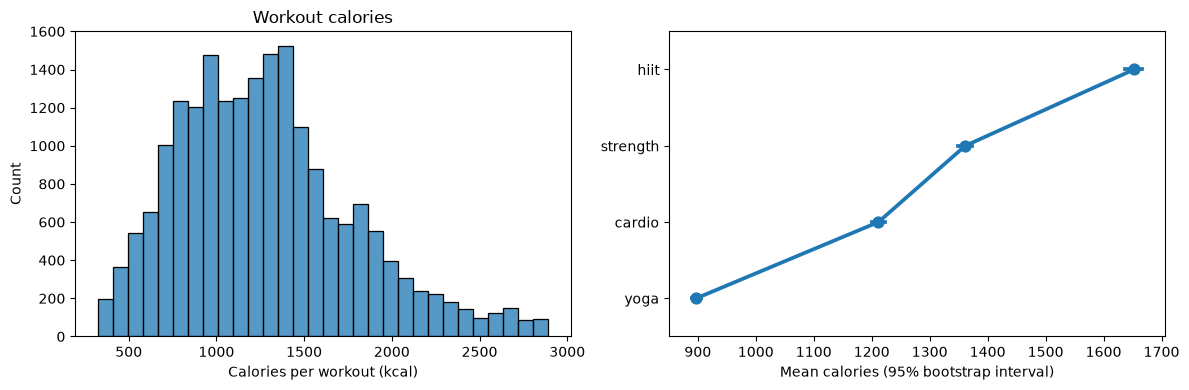

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=workouts, x="calories", bins=30, ax=axes[0])
axes[0].set(xlabel="Calories per workout (kcal)", title="Workout calories")

sns.pointplot(
    data=workouts,
    x="calories",
    y="workout_type",
    order=["hiit", "strength", "cardio", "yoga"],
    errorbar=("ci", 95),
    seed=42,
    ax=axes[1],
)
axes[1].set(xlabel="Mean calories (95% bootstrap interval)", ylabel="")
plt.tight_layout()
plt.show()



The bars in the left panel describe individual recorded workouts; the intervals in the right panel describe uncertainty in group **means**. Overlap between two separate intervals is not itself a formal test of their difference. Use the direct interval for the difference when that is the question.

## 5.8 A checklist for reporting estimates

Before sharing an estimate, check that you have:

1. defined the target population, parameter and observational unit;
2. described how the sample was obtained and whether records are independent;
3. stated the variables, units, eligibility rules and cleaning decisions;
4. reported the point estimate and an interval in interpretable units;
5. named the method and checked whether its assumptions are plausible; and
6. distinguished sampling uncertainty from bias, measurement error and causation.

### Check your understanding

1. What is the difference between an estimator and its realised point estimate?
2. In repeated sampling, what does a 95% confidence level describe?
3. Why might a Wilson interval be preferred to the basic normal interval for a proportion?
4. If the sample size is multiplied by four, approximately how does the standard error of the mean change?
5. Why can a large number of workout records still give misleading uncertainty estimates?

### Lab 5: Calories & Workouts

Reproduce the results above, then try another threshold or compare different workout types:

- the mean calories per recorded workout, its SE and 95% $t$ interval;
- the mean difference between two workout types with a Welch 95% interval;
- the proportion meeting a clearly stated threshold, with both normal and Wilson intervals;
- approximate sample sizes for a mean margin of error of 25 kcal and a proportion margin of error of 0.05; and
- a histogram and a group-mean plot with 95% intervals.

For each result, state what the observations represent, how missing or implausible values were handled, and whether repeated measurements from the same person affect the independence assumption.
